2026-04-08. Updated 2026-05-07

Shahlo Solieva

Use this notebook to plot per resi RMSF (aligned by sequence) with (mature) crystal structure minimum distance values. 

In [1]:
import numpy as np
import mdtraj as md
import matplotlib.pyplot as plt
import itertools
import pandas as pd

# Helper functions

In [2]:
# Paths
base_path='/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/RMSF'
df_base_path =f'{base_path}/data/seq_alignments/naive_aligned'
fig_base_path=f'../figures/manuscript/'
glycan_base_path='/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/distance_to_antigen/data/to_glycan/'
protein_base_path='/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/distance_to_antigen/data/to_protein/'

In [3]:
def translate_resname_to_rescode(resi_list):
    resname_to_rescode_definition =[[
        'ALA','ARG','ASN','ASP','CYS','GLU','GLN',\
        'GLY','HIS','ILE','LEU','LYS','MET','PHE',\
        'PRO','SER','THR','TRP','TYR','VAL'],\
        ['A'  ,'R'  ,'N'  ,'D'  ,'C'  ,'E'  ,'Q'  ,\
        'G'  ,'H'  ,'I'  ,'L'  ,'K'  ,'M'  ,'F'  ,\
        'P'  ,'S'  ,'T'  ,'W'  ,'Y'  ,'V' ]]
    single_code_resi_list = []
    for i in range(len(resi_list)):
        if len(resi_list[i]) > 1: # if there is a value, then continue.
            resname = str(resi_list[i][0:3])
            res_number = str(resi_list[i][3:])
            for j in range(len(resname_to_rescode_definition[0])):
                if resname == resname_to_rescode_definition[0][j]:
                    single_code_resi_list.append(f'{resname_to_rescode_definition[1][j]}{res_number}')
        if len(resi_list[i]) <= 1: # if there is no value, just append a space.
            single_code_resi_list.append(' ')
    return single_code_resi_list

In [5]:
def plot_per_residue(lineage, which_chain,  df, y_max, df_data_names, df_stds_names, df_resi_names, colors, labels, figname, distance, variable_name, subtitle):
    df_glycan    = pd.read_csv(f"{glycan_base_path}{lineage}_{which_chain}.csv")
    df_protein   = pd.read_csv(f"{protein_base_path}{lineage}_{which_chain}.csv")
    glycan_dists = df_glycan[f'pdb_mature_{which_chain}_glycan_minDists']
    protein_dists= df_protein[f'pdb_mature_{which_chain}_protein_minDists']

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=[3.8,1.3], height_ratios=[3, 0.2,0.2] , gridspec_kw=dict(hspace=0))
    small_fontsize = 6
    data_names =['naive','mature']

    low_cis = []
    high_cis = []
    rmsfs = []
    for i in range(len(data_names)):
        data_name = data_names[i]
        rmsf=  df[f'{data_name}_{which_chain}_rmsf']
        low_ci =df[f'{data_name}_{which_chain}_rmsf_ci_low']
        high_ci=df[f'{data_name}_{which_chain}_rmsf_ci_high']
        low_cis.append(low_ci)
        high_cis.append(high_ci)
        rmsfs.append(rmsf)
        x = np.arange(1, 1+len(rmsf))
        ax1.plot(x, rmsf,                    color=colors[i], label=labels[i], linewidth=0.8)
        ax1.fill_between(x, low_ci, high_ci, color=colors[i], alpha=0.6, linewidth=0.5)

    
    for i in range(len(low_cis[0])):
        lower = max(low_cis[0][i], low_cis[1][i])
        higher = min(high_cis[0][i], high_cis[1][i])
        #print(lower, higher)
        if lower > higher: # no overlap, significant! 
            if protein_dists[i] < distance:
                ax2.scatter(x[i],0.5, color='0.4',    s=20, zorder=1, edgecolor='k', linewidth=0.6, alpha=0.8)#, linestyle='-', linewidth=2)
            if glycan_dists[i] < distance:
                ax3.scatter(x[i],0.5, color='orange', s=20, zorder=1, edgecolor='k', linewidth=0.6, alpha=0.8)#, linestyle='-', linewidth=2)
        if lower < higher:
            if protein_dists[i] < distance:
                ax2.scatter(x[i],0.5, color='0.4',    s=20, zorder=1, edgecolor='k', linewidth=0.6, alpha=0.5)#, linestyle='-', linewidth=2)
            if glycan_dists[i] < distance:
                ax3.scatter(x[i],0.5, color='orange', s=20, zorder=1, edgecolor='k', linewidth=0.6, alpha=0.5)#, linestyle='-', linewidth=2)

        if np.isnan(low_cis[0][i]) or np.isnan(low_cis[1][i]):
            if glycan_dists[i] < distance:
                ax3.scatter(x[i],0.5, color='orange', s=20, zorder=1, edgecolor='k', linewidth=0.6, alpha=0.8)#, linestyle='-', linewidth=2)
            if protein_dists[i] < distance:
                ax2.scatter(x[i],0.5, color='0.4',    s=20, zorder=1, edgecolor='k', linewidth=0.6, alpha=0.8)#, linestyle='-', linewidth=2)

            # custom x ticks 
    naive_resi=  df[f'naive_{which_chain}_resi']
    mature_resi=  df[f'mature_{which_chain}_resi']
    x_ticks_index = np.arange(1, 1+len(naive_resi))
    x_ticks_naive_resi  = translate_resname_to_rescode(naive_resi.fillna(' '))
    x_ticks_mature_resi = translate_resname_to_rescode(mature_resi.fillna(' '))
    x_ticks_final = []
    for i in range(len(x_ticks_index)):
        x_ticks_final.append(f'{x_ticks_naive_resi[i]}\n{x_ticks_mature_resi[i]}')
    ax3.set_xticks(x_ticks_index[::20])
    ax3.set_xticklabels( x_ticks_final[::20], fontsize=small_fontsize)
    # set yticks 
    if y_max > 10:
        ax1.set_yticks([0,4,8,12,16,20]) 
        ax1.set_yticklabels([0,4,8,12,16,20], fontsize=small_fontsize)
    if y_max <= 10:
        ax1.set_yticks([0,2,4,6,8]) 
        ax1.set_yticklabels([0,2,4,6,8], fontsize=small_fontsize)
    # set title
    if which_chain == 'HC':
        if lineage=='Ab118':
            ax1.set_title(f"1-18 lineage: Variable HC RMSF | {subtitle}", fontsize=small_fontsize, weight='bold', pad = 0)
        else: 
            ax1.set_title(f"{lineage} lineage: Variable HC RMSF | {subtitle}", fontsize=small_fontsize, weight='bold', pad = 0)

    if which_chain == 'LC':
        if lineage=='Ab118':
            ax1.set_title(f"1-18 lineage: Variable LC RMSF | {subtitle}", fontsize=small_fontsize, weight='bold', pad = 0)
        else: 
            ax1.set_title(f"{lineage} lineage: Variable LC RMSF | {subtitle}", fontsize=small_fontsize, weight='bold', pad = 0)
    ax1.set_ylabel(f'CA RMSF'+r' ($\mathbf{\AA}$)', fontsize=small_fontsize, weight='bold', labelpad=0)
    ax3.set_xlabel("Residue", fontsize=small_fontsize, weight='bold', labelpad=0)
    ax1.set_ylim(0,y_max)
    ax2.set_yticks([])
    ax2.set_ylim(0,1)
    ax3.set_yticks([])
    ax3.set_ylim(0,1)
    ax1.legend(ncol=2, fontsize=small_fontsize, loc='upper center', markerscale=2.0)
    plt.subplots_adjust(wspace=0)
    plt.savefig(f'{fig_base_path}/FigS15_S21_RMSF_per_residue_naive_aligned_{figname}_protein_glycan_distances_cutoff_{distance}A_{variable_name}.pdf', dpi=300, transparent=True, bbox_inches='tight')
    plt.show()

# Plots

## All

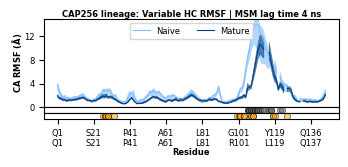

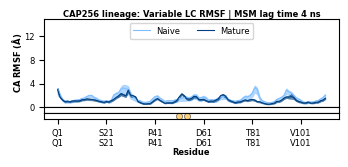

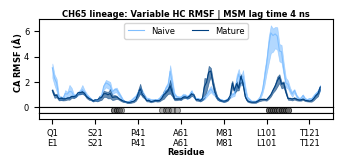

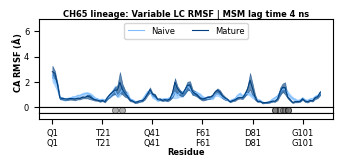

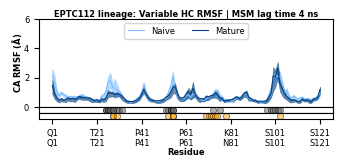

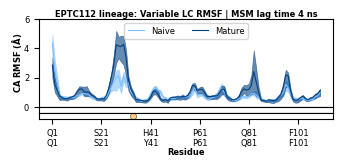

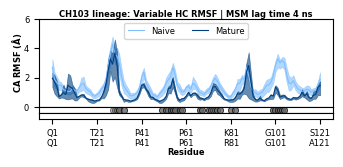

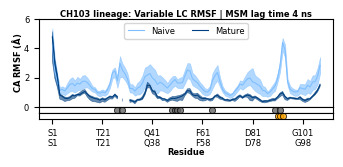

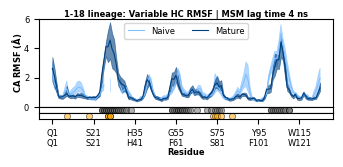

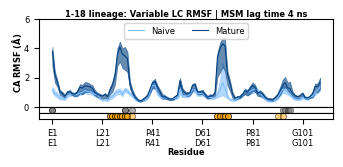

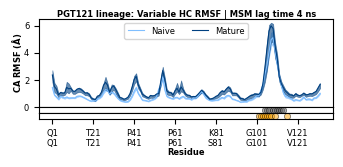

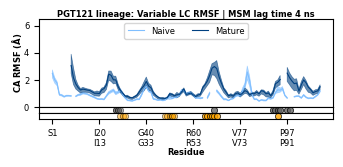

In [6]:
lineages = ['CAP256','CH65', 'EPTC112','CH103', 'Ab118', 'PGT121'] #Ab118
y_max_list =  [15, 7, 6, 6, 6, 6.5]#6.5

variable_name = 'lagtime200'
subtitle = 'MSM lag time 4 ns'
for i, lineage in enumerate(lineages):
    colors=['#80bfff','#004080']
    data_name='mature'
    labels=['Naive', 'Mature']
    y_max = y_max_list[i]

    which_chain = 'HC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    df_data_names = [f'naive_{which_chain}_rmsf',    f'{data_name}_{which_chain}_rmsf']
    df_stds_names = [f'naive_{which_chain}_rmsf_std',f'{data_name}_{which_chain}_rmsf_std']
    df_resi_names = [f'naive_{which_chain}_resi',    f'{data_name}_{which_chain}_resi']
    plot_per_residue(lineage, which_chain, df, y_max, df_data_names, df_stds_names, df_resi_names, colors, labels, figname, 6, variable_name, subtitle)

    which_chain = 'LC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    df_data_names = [f'naive_{which_chain}_rmsf',    f'{data_name}_{which_chain}_rmsf']
    df_stds_names = [f'naive_{which_chain}_rmsf_std',f'{data_name}_{which_chain}_rmsf_std']
    df_resi_names = [f'naive_{which_chain}_resi',    f'{data_name}_{which_chain}_resi']
    plot_per_residue(lineage, which_chain, df, y_max, df_data_names, df_stds_names, df_resi_names, colors, labels, figname,6, variable_name, subtitle)

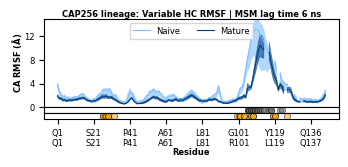

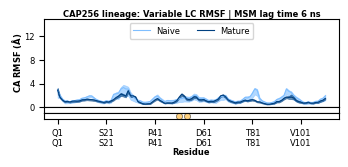

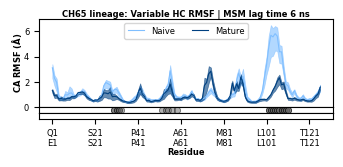

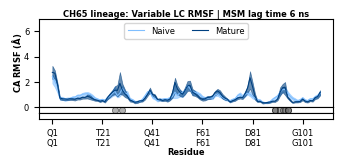

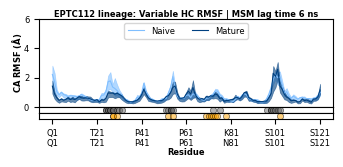

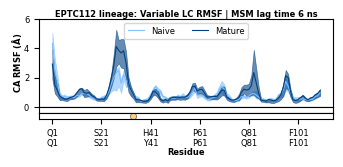

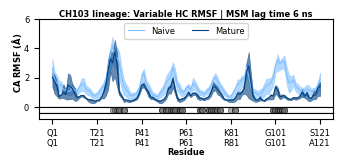

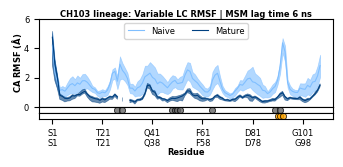

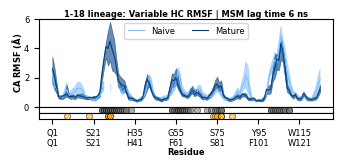

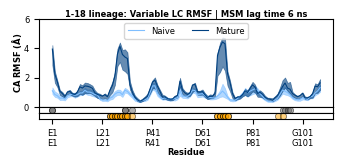

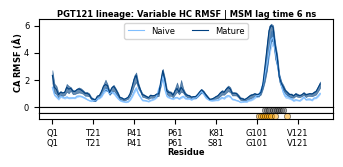

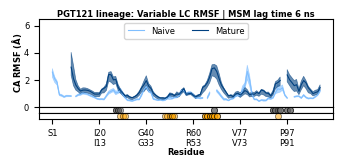

In [7]:
lineages = ['CAP256','CH65', 'EPTC112','CH103', 'Ab118', 'PGT121'] #Ab118
y_max_list =  [15, 7, 6, 6, 6, 6.5]#6.5

variable_name = 'lagtime300'
subtitle = 'MSM lag time 6 ns'
for i, lineage in enumerate(lineages):
    colors=['#80bfff','#004080']
    data_name='mature'
    labels=['Naive', 'Mature']
    y_max = y_max_list[i]

    which_chain = 'HC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    df_data_names = [f'naive_{which_chain}_rmsf',    f'{data_name}_{which_chain}_rmsf']
    df_stds_names = [f'naive_{which_chain}_rmsf_std',f'{data_name}_{which_chain}_rmsf_std']
    df_resi_names = [f'naive_{which_chain}_resi',    f'{data_name}_{which_chain}_resi']
    plot_per_residue(lineage, which_chain, df, y_max, df_data_names, df_stds_names, df_resi_names, colors, labels, figname, 6, variable_name, subtitle)

    which_chain = 'LC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    df_data_names = [f'naive_{which_chain}_rmsf',    f'{data_name}_{which_chain}_rmsf']
    df_stds_names = [f'naive_{which_chain}_rmsf_std',f'{data_name}_{which_chain}_rmsf_std']
    df_resi_names = [f'naive_{which_chain}_resi',    f'{data_name}_{which_chain}_resi']
    plot_per_residue(lineage, which_chain, df, y_max, df_data_names, df_stds_names, df_resi_names, colors, labels, figname,6, variable_name, subtitle)

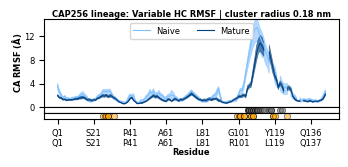

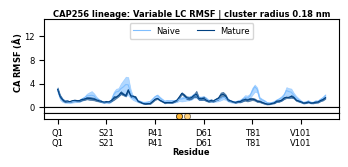

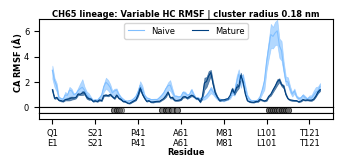

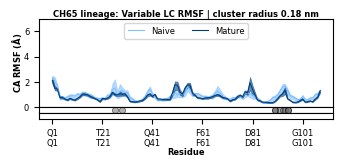

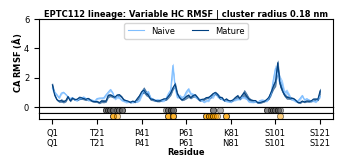

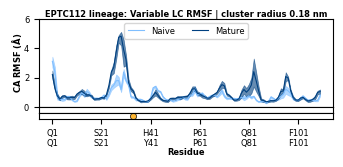

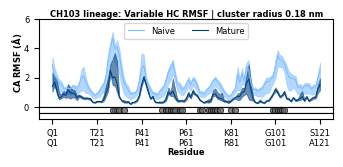

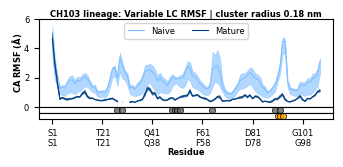

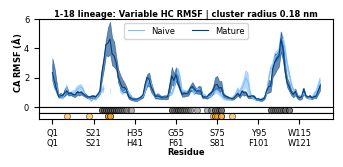

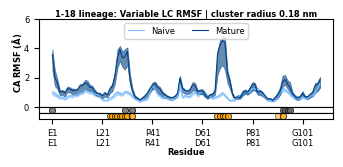

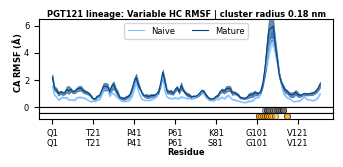

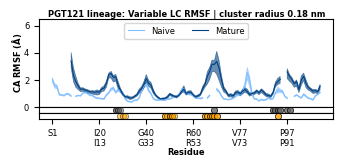

In [8]:
lineages = ['CAP256','CH65', 'EPTC112','CH103', 'Ab118', 'PGT121'] #Ab118
y_max_list =  [15, 7, 6, 6, 6, 6.5]#6.5

variable_name = 'radius18'
subtitle = 'cluster radius 0.18 nm'
for i, lineage in enumerate(lineages):
    colors=['#80bfff','#004080']
    data_name='mature'
    labels=['Naive', 'Mature']
    y_max = y_max_list[i]

    which_chain = 'HC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    df_data_names = [f'naive_{which_chain}_rmsf',    f'{data_name}_{which_chain}_rmsf']
    df_stds_names = [f'naive_{which_chain}_rmsf_std',f'{data_name}_{which_chain}_rmsf_std']
    df_resi_names = [f'naive_{which_chain}_resi',    f'{data_name}_{which_chain}_resi']
    plot_per_residue(lineage, which_chain, df, y_max, df_data_names, df_stds_names, df_resi_names, colors, labels, figname, 6, variable_name, subtitle)

    which_chain = 'LC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    df_data_names = [f'naive_{which_chain}_rmsf',    f'{data_name}_{which_chain}_rmsf']
    df_stds_names = [f'naive_{which_chain}_rmsf_std',f'{data_name}_{which_chain}_rmsf_std']
    df_resi_names = [f'naive_{which_chain}_resi',    f'{data_name}_{which_chain}_resi']
    plot_per_residue(lineage, which_chain, df, y_max, df_data_names, df_stds_names, df_resi_names, colors, labels, figname,6, variable_name, subtitle)

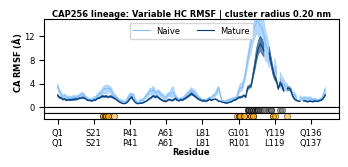

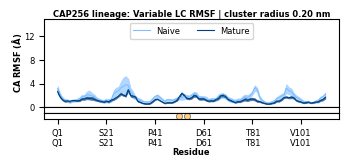

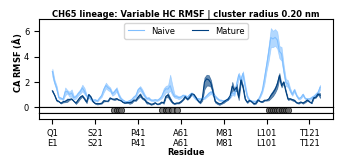

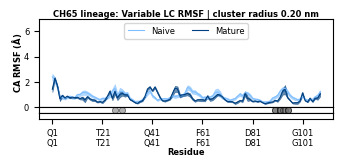

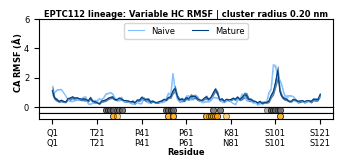

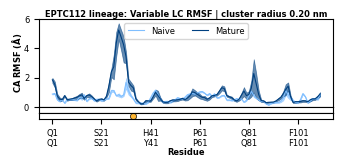

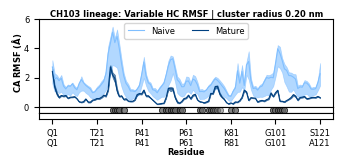

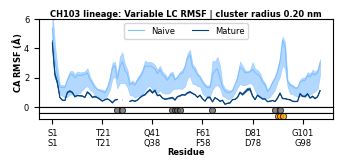

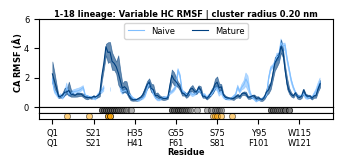

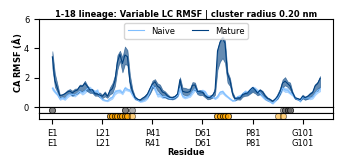

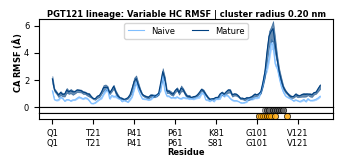

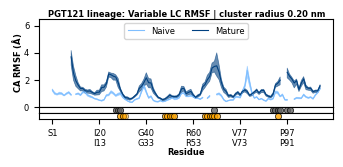

In [9]:
lineages = ['CAP256','CH65', 'EPTC112','CH103', 'Ab118', 'PGT121'] #Ab118
y_max_list =  [15, 7, 6, 6, 6, 6.5]#6.5

variable_name = 'radius20'
subtitle = 'cluster radius 0.20 nm'
for i, lineage in enumerate(lineages):
    colors=['#80bfff','#004080']
    data_name='mature'
    labels=['Naive', 'Mature']
    y_max = y_max_list[i]

    which_chain = 'HC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    df_data_names = [f'naive_{which_chain}_rmsf',    f'{data_name}_{which_chain}_rmsf']
    df_stds_names = [f'naive_{which_chain}_rmsf_std',f'{data_name}_{which_chain}_rmsf_std']
    df_resi_names = [f'naive_{which_chain}_resi',    f'{data_name}_{which_chain}_resi']
    plot_per_residue(lineage, which_chain, df, y_max, df_data_names, df_stds_names, df_resi_names, colors, labels, figname, 6, variable_name, subtitle)

    which_chain = 'LC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    df_data_names = [f'naive_{which_chain}_rmsf',    f'{data_name}_{which_chain}_rmsf']
    df_stds_names = [f'naive_{which_chain}_rmsf_std',f'{data_name}_{which_chain}_rmsf_std']
    df_resi_names = [f'naive_{which_chain}_resi',    f'{data_name}_{which_chain}_resi']
    plot_per_residue(lineage, which_chain, df, y_max, df_data_names, df_stds_names, df_resi_names, colors, labels, figname,6, variable_name, subtitle)

# 3f8

In [10]:
import numpy as np
import mdtraj as md
import matplotlib.pyplot as plt
import itertools
import pandas as pd

# Paths
base_path='/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/RMSF'
df_base_path =f'{base_path}/data/seq_alignments/naive_aligned'
fig_base_path=f'../figures'

def translate_resname_to_rescode(resi_list):
    resname_to_rescode_definition =[[
        'ALA','ARG','ASN','ASP','CYS','GLU','GLN',\
        'GLY','HIS','ILE','LEU','LYS','MET','PHE',\
        'PRO','SER','THR','TRP','TYR','VAL'],\
        ['A'  ,'R'  ,'N'  ,'D'  ,'C'  ,'E'  ,'Q'  ,\
        'G'  ,'H'  ,'I'  ,'L'  ,'K'  ,'M'  ,'F'  ,\
        'P'  ,'S'  ,'T'  ,'W'  ,'Y'  ,'V' ]]
    single_code_resi_list = []
    for i in range(len(resi_list)):
        if len(resi_list[i]) > 1: # if there is a value, then continue.
            resname = str(resi_list[i][0:3])
            res_number = str(resi_list[i][3:])
            for j in range(len(resname_to_rescode_definition[0])):
                if resname == resname_to_rescode_definition[0][j]:
                    single_code_resi_list.append(f'{resname_to_rescode_definition[1][j]}{res_number}')
        if len(resi_list[i]) <= 1: # if there is no value, just append a space.
            single_code_resi_list.append(' ')
    return single_code_resi_list

In [11]:
def plot_per_residue(lineage, which_chain,  df, y_max, colors, labels, figname, glycan_contacts, variable_name,subtitle):
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=[3.8,1.3], height_ratios=[3, 0.2,0.2] , gridspec_kw=dict(hspace=0))
    small_fontsize = 6
    data_names =['naive','mature']

    # custom x ticks 
    naive_resi=  df[f'naive_{which_chain}_resi']
    mature_resi=  df[f'mature_{which_chain}_resi']
    x_ticks_index = np.arange(1, 1+len(naive_resi))
    x_ticks_naive_resi  = translate_resname_to_rescode(naive_resi.fillna(' '))
    x_ticks_mature_resi = translate_resname_to_rescode(mature_resi.fillna(' '))
    x_ticks_final = []
    for i in range(len(x_ticks_index)):
        x_ticks_final.append(f'{x_ticks_naive_resi[i]}\n{x_ticks_mature_resi[i]}')    

    low_cis = []
    high_cis = []
    for i in range(len(data_names)):
        data_name = data_names[i]
        rmsf=  df[f'{data_name}_{which_chain}_rmsf']
        low_ci =df[f'{data_name}_{which_chain}_rmsf_ci_low']
        high_ci=df[f'{data_name}_{which_chain}_rmsf_ci_high']
        x = np.arange(1, 1+len(rmsf))
        ax1.plot(x, rmsf,                    color=colors[i], label=labels[i], linewidth=0.8)
        ax1.fill_between(x, low_ci, high_ci, color=colors[i], alpha=0.6, linewidth=0.5)
        low_cis.append(low_ci)
        high_cis.append(high_ci)


    for i in range(len(glycan_contacts)):
        resi_index = glycan_contacts[i]
        print(x_ticks_final[resi_index-1]) # x ticks final is 1-based so subtract 1 here. 
        lower = max(low_cis[0][resi_index], low_cis[1][resi_index])
        higher = min(high_cis[0][resi_index], high_cis[1][resi_index])
        if lower > higher: # no overlap, significant! 
            ax3.scatter(glycan_contacts[i],0.5, color='orange', s=20, zorder=1, edgecolor='k', linewidth=0.6, alpha=0.8)#, linestyle='-', linewidth=2)
        if lower < higher: # no overlap, significant! 
            ax3.scatter(glycan_contacts[i],0.5, color='orange', s=20, zorder=1, edgecolor='k', linewidth=0.6, alpha=0.5)#, linestyle='-', linewidth=2)

    ax3.set_xticks(x_ticks_index[::20])
    ax3.set_xticklabels( x_ticks_final[::20], fontsize=small_fontsize)

    # set yticks 
    ax1.set_yticks([0,2,4,6,8]) 
    ax1.set_yticklabels([0,2,4,6,8], fontsize=small_fontsize)
    # set title
    #if which_chain == 'HC':
    #    ax1.title(f"{lineage} lineage: Variable HC rmsf", fontsize=small_fontsize, weight='bold', pad = 0)
    #if which_chain == 'LC':
    #    ax1.title(f"{lineage} lineage: Variable LC rmsf", fontsize=small_fontsize, weight='bold', pad = 0)
    if which_chain == 'HC':
        ax1.set_title(f"3F8 lineage: Variable HC RMSF | {subtitle}", fontsize=small_fontsize, weight='bold', pad = 0)
    if which_chain == 'LC':
        ax1.set_title(f"3F8 lineage: Variable LC RMSF | {subtitle}", fontsize=small_fontsize, weight='bold', pad = 0)

    ax1.set_ylabel(f'CA RMSF'+r' ($\mathbf{\AA}$)', fontsize=small_fontsize, weight='bold', labelpad=0)
    ax3.set_xlabel("Residue", fontsize=small_fontsize, weight='bold', labelpad=0)
    ax1.set_ylim(0,y_max)
    ax2.set_yticks([])
    ax2.set_ylim(0,1)
    ax3.set_yticks([])
    ax3.set_ylim(0,1)
    ax1.legend(ncol=2, fontsize=small_fontsize, loc='upper center', markerscale=2.0)
    plt.subplots_adjust(wspace=0)
    plt.savefig(f'../figures/FigS21_RMSF_per_residue_naive_aligned_3F8_{which_chain}_protein_glycan_distances_{variable_name}.pdf', dpi=300, transparent=True, bbox_inches='tight')
    plt.show()

Y32
Y32
A53
A53
G54
G54
S56
I56
N58
N58
R98
R98
H101
H101
G103
G103
Y104
Y104


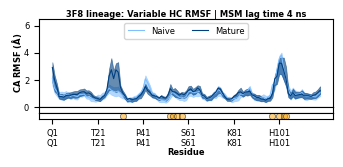

Y92
Y92


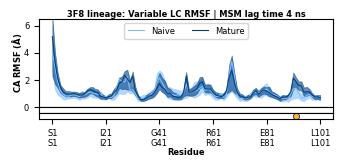

In [12]:
lineages = ['Ab3F8']
y_max_list = [6.5]

variable_name = 'lagtime200'
subtitle = 'MSM lag time 4 ns'

for i, lineage in enumerate(lineages):
    colors=['#80bfff','#004080']
    data_name='mature'
    labels=['Naive', 'Mature']
    y_max = y_max_list[i]

    which_chain = 'HC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    plot_per_residue(lineage, which_chain, df, y_max, colors, labels, figname, [32,53,54,56,58,98,101 ,103,104], variable_name, subtitle)
    which_chain = 'LC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    plot_per_residue(lineage, which_chain, df, y_max, colors, labels, figname, [92], variable_name, subtitle)

Y32
Y32
A53
A53
G54
G54
S56
I56
N58
N58
R98
R98
H101
H101
G103
G103
Y104
Y104


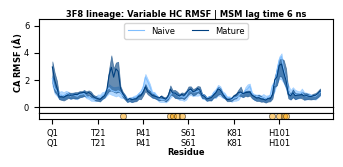

Y92
Y92


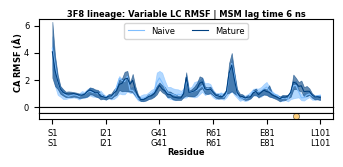

In [13]:
lineages = ['Ab3F8']
y_max_list = [6.5]

variable_name = 'lagtime300'
subtitle = 'MSM lag time 6 ns'

for i, lineage in enumerate(lineages):
    colors=['#80bfff','#004080']
    data_name='mature'
    labels=['Naive', 'Mature']
    y_max = y_max_list[i]

    which_chain = 'HC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    plot_per_residue(lineage, which_chain, df, y_max, colors, labels, figname, [32,53,54,56,58,98,101 ,103,104], variable_name, subtitle)
    which_chain = 'LC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    plot_per_residue(lineage, which_chain, df, y_max, colors, labels, figname, [92], variable_name, subtitle)

Y32
Y32
A53
A53
G54
G54
S56
I56
N58
N58
R98
R98
H101
H101
G103
G103
Y104
Y104


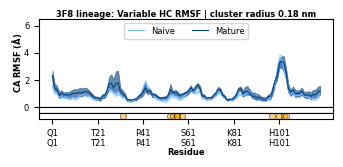

Y92
Y92


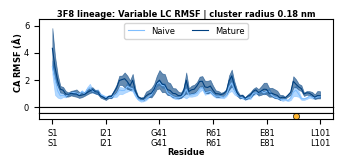

In [14]:
lineages = ['Ab3F8']
y_max_list = [6.5]

variable_name = 'radius18'
subtitle = 'cluster radius 0.18 nm'

for i, lineage in enumerate(lineages):
    colors=['#80bfff','#004080']
    data_name='mature'
    labels=['Naive', 'Mature']
    y_max = y_max_list[i]

    which_chain = 'HC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    plot_per_residue(lineage, which_chain, df, y_max, colors, labels, figname, [32,53,54,56,58,98,101 ,103,104], variable_name, subtitle)
    which_chain = 'LC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    plot_per_residue(lineage, which_chain, df, y_max, colors, labels, figname, [92], variable_name, subtitle)

Y32
Y32
A53
A53
G54
G54
S56
I56
N58
N58
R98
R98
H101
H101
G103
G103
Y104
Y104


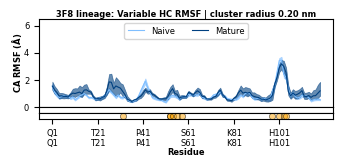

Y92
Y92


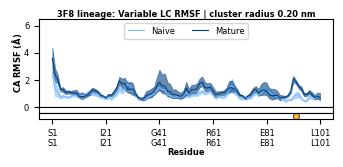

In [15]:
variable_name = 'radius20'
subtitle = 'cluster radius 0.20 nm'

for i, lineage in enumerate(lineages):
    colors=['#80bfff','#004080']
    data_name='mature'
    labels=['Naive', 'Mature']
    y_max = y_max_list[i]

    which_chain = 'HC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    plot_per_residue(lineage, which_chain, df, y_max, colors, labels, figname, [32,53,54,56,58,98,101 ,103,104], variable_name, subtitle)
    which_chain = 'LC'
    figname=f'{lineage}_{which_chain}'
    df = pd.read_csv(f"{df_base_path}/{lineage}_mature_aligned_to_naive_{which_chain}_{variable_name}.csv")  
    plot_per_residue(lineage, which_chain, df, y_max, colors, labels, figname, [92], variable_name, subtitle)